In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import geopandas as gpd
from scipy.stats import linregress

In [2]:
stations_folder = Path(r'C:\Users\jjd83\Downloads\Station_Data')
station_dfs = {}
for station_csv in stations_folder.glob('*.csv'):
    name = station_csv.name.split("/",5)[-1].removesuffix(".csv")
    station_dfs[name] = pd.read_csv(station_csv)

In [3]:
#used https://www.askpython.com/python-modules/pandas/groupby-to-group-dataframe-by-month
monthly_station_dfs = {}
for name, station_df in station_dfs.items():
    station_df['obsTimeLocal'] = pd.to_datetime(station_df['obsTimeLocal'])
    monthly_station_df = station_df.groupby(station_df['obsTimeLocal'].dt.month).mean(numeric_only=True)
    monthly_station_df['Month'] = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
    monthly_station_df.index = monthly_station_df['Month']
    monthly_station_df = monthly_station_df.drop(columns='Month')
    monthly_station_dfs[name] = monthly_station_df

In [4]:
# #bar charts
# for name, monthly_station_df in monthly_station_dfs.items():
#     monthly_station_df.dropna(axis=0, inplace= True)
#     if len(monthly_station_df) == 12:
#         for metric in monthly_station_df.columns:
#             monthly_station_df.plot(kind='bar',y=f"{metric}", figsize=(7,7))
#             if "temp" in metric:
#                 plt.ylabel(f"{metric} (degrees Celsius)")
#             elif "solar" in metric:
#                 plt.ylabel(f"{metric} (W/m^2)")
#             elif "humidity" in metric:
#                 plt.ylabel(f"{metric} (%)")
#             elif "heat" in metric:
#                 plt.ylabel(f"{metric} (degrees Celsius)")
#             plt.title(f"{metric} for {name}")
#             plt.axhline(0, color='black', linewidth=1.5, linestyle='-')
#             plt.savefig(rf'C:\Users\jjd83\Downloads\Station_Bar_Charts\{name}_{metric}.png')
#             plt.close()

In [4]:
#getting in station locations
station_info = pd.read_csv(r"C:\Users\jjd83\Downloads\100mbuffer_BSECstations_gee.csv")
station_location = pd.DataFrame()
station_location_data = []
updated_station_dfs = {}
station_locations = {}
for row in station_info.itertuples():
    station_location_data.append({"Station": f"{row.stationtype}_{row.stationID}",
    "Longitude": row.lon, "Latitude": row.lat})
station_location = pd.DataFrame(station_location_data)
station_location.set_index('Station', inplace=True)
for station_name, station_df in station_dfs.items():
    station_name = station_name.replace('_BSEC', '')
    station_df.set_index('obsTimeLocal',inplace=True)
    updated_station_dfs[station_name] = station_df

<Axes: >

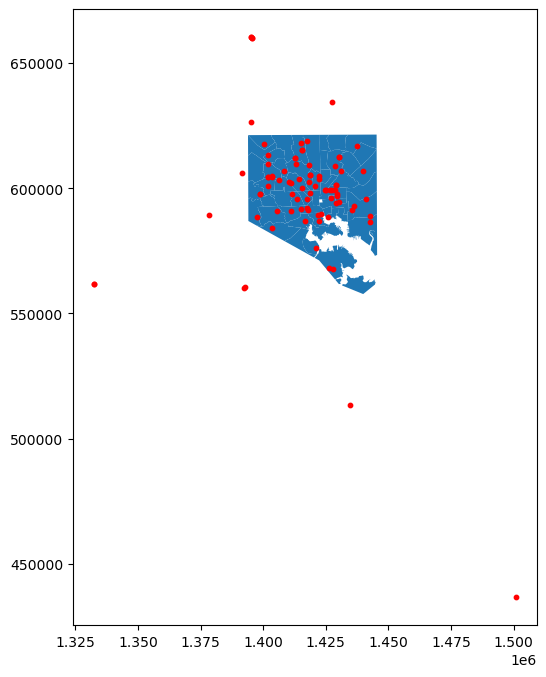

In [5]:
baltimore = gpd.read_file(r"C:\Users\jjd83\Downloads\Percent_of_Residences_Heated_by_Electricity_-_Community_Statistical_Area\Percent_of_Residences_Heated_by_Electricity_-_Community_Statistical_Area.dbf")
fig, ax = plt.subplots(figsize=(8,8))
baltimore.plot(ax=ax)
station_gdf = gpd.GeoDataFrame(station_location,geometry=gpd.points_from_xy(station_location['Longitude'], station_location['Latitude']))
#next two lines from troubleshooting in gemini
station_gdf = station_gdf.set_crs("EPSG:4326")
station_gdf = station_gdf.to_crs(baltimore.crs)
station_gdf.plot(ax=ax, color='red', markersize=10, zorder=5, label='Stations')
# plt.legend()
# plt.show()
#remove the stations not in baltimore pls

In [8]:
#added locations to station data
summary_dfs = {}
for station_name, station_df in updated_station_dfs.items():
    if station_name in station_location.index:
        station_df['Longitude'] = station_location.loc[station_name,'Longitude']
        station_df['Latitude'] = station_location.loc[station_name,'Latitude']
        summary_dfs[station_name] = station_df

In [9]:
summary_station_dfs = {}
for station_name, station_df in updated_station_dfs.items():
    winter_months = station_df.index.month.isin([12,1,2])
    spring_months = station_df.index.month.isin([3,4,5])
    summer_months = station_df.index.month.isin([6,7,8])
    autumn_months = station_df.index.month.isin([9,10,11])
    station_df.loc[winter_months, 'Season'] = 'DJF'
    station_df.loc[spring_months, 'Season'] = 'MAM'
    station_df.loc[summer_months, 'Season'] = 'JJA'
    station_df.loc[autumn_months, 'Season'] = 'SON'
    summary_station_dfs[station_name] = station_df.groupby('Season').mean()
summary_station_dfs

{'AWS_AAC':          dewptAvg  dewptHigh   dewptLow  heatindexAvg  heatindexHigh  \
 Season                                                                 
 DJF     -2.676028  -2.197844  -3.127385      3.263393       3.684491   
 JJA     18.029294  18.729686  17.431866     26.089211      26.971731   
 MAM      6.038179   6.758552   5.423001     13.515003      14.078255   
 SON      9.516672  10.039622   9.039401     15.471334      16.057520   
 
         heatindexLow  humidityAvg  humidityHigh  humidityLow  \
 Season                                                         
 DJF         2.847146    67.509261     69.723553    65.362475   
 JJA        25.292001    67.939189     71.032912    64.996077   
 MAM        12.972067    64.345359     67.176299    61.740222   
 SON        14.914171    70.562402     73.181694    68.011398   
 
         solarRadiationHigh    tempAvg   tempHigh    tempLow  Longitude  \
 Season                                                                   
 DJF   

In [10]:
#maybe add units 
master_summary_df = pd.concat(summary_station_dfs.values())
master_summary_df = master_summary_df.reset_index()
winter_summary_df = master_summary_df[master_summary_df['Season']=='DJF']
spring_summary_df = master_summary_df[master_summary_df['Season']=='MAM']
summer_summary_df = master_summary_df[master_summary_df['Season']=='JJA']
autumn_summary_df = master_summary_df[master_summary_df['Season']=='SON']
winter_gdf = gpd.GeoDataFrame(winter_summary_df,geometry=gpd.points_from_xy(winter_summary_df.Longitude,winter_summary_df.Latitude),crs="EPSG:4326").to_crs(baltimore.crs)
filtered_winter_points = winter_gdf.geometry.within(baltimore.geometry.unary_union)
filtered_winter_gdf = winter_gdf[filtered_winter_points]
spring_gdf = gpd.GeoDataFrame(spring_summary_df,geometry=gpd.points_from_xy(spring_summary_df.Longitude,spring_summary_df.Latitude),crs="EPSG:4326").to_crs(baltimore.crs)
filtered_spring_points = spring_gdf.geometry.within(baltimore.geometry.unary_union)
filtered_spring_gdf = spring_gdf[filtered_spring_points]
summer_gdf = gpd.GeoDataFrame(summer_summary_df,geometry=gpd.points_from_xy(summer_summary_df.Longitude,summer_summary_df.Latitude),crs="EPSG:4326").to_crs(baltimore.crs)
filtered_summer_points = summer_gdf.geometry.within(baltimore.geometry.unary_union)
filtered_summer_gdf = summer_gdf[filtered_summer_points]
autumn_gdf = gpd.GeoDataFrame(autumn_summary_df,geometry=gpd.points_from_xy(autumn_summary_df.Longitude,autumn_summary_df.Latitude),crs="EPSG:4326").to_crs(baltimore.crs)
filtered_autumn_points = autumn_gdf.geometry.within(baltimore.geometry.unary_union)
filtered_autumn_gdf = autumn_gdf[filtered_autumn_points]
# for metric in master_summary_df.columns:
# # might want to adjust this to be smaller with a dictionary
#     if metric in ['dewptAvg','dewptHigh','dewptLow','heatindexAvg','heatindexHigh','heatindexLow','humidityAvg','humidityHigh','humidityLow','solarRadiationHigh','tempAvg','tempHigh','tempLow']:
#         if metric == 'dewptAvg':
#             metric_title = "Dew Point Temperature (Average)"
#         elif metric == 'dewptHigh':
#             metric_title = "Dew Point Temperature (High)"
#         elif metric == 'dewptLow':
#             metric_title = "Dew Point Temperature (Low)"
#         elif metric == 'heatindexAvg':
#             metric_title = "Heat Index (Average)"
#         elif metric == 'heatindexHigh':
#             metric_title = "Heat Index (High)"
#         elif metric == 'heatindexLow':
#             metric_title = "Heat Index (Low)"
#         elif metric == 'humidityAvg':
#             metric_title = "Humidity (Average)"
#         elif metric == 'humidityHigh':
#             metric_title = "Humidity (High)"
#         elif metric == 'humidityLow':
#             metric_title = "Humidity (Low)"
#         elif metric == 'solarRadiationHigh':
#             metric_title = "Solar Radiation"
#         elif metric == 'tempAvg':
#             metric_title = "Temperature (Average)"
#         elif metric == 'tempHigh':
#             metric_title = "Temperature (High)"    
#         elif metric == 'tempLow':
#             metric_title = "Temperature (Low)"
#         fig, ax = plt.subplots(2,2,figsize=(14,12), sharex=True, sharey=True)
#         baltimore.plot(ax=ax[0,0])
#         baltimore.plot(ax=ax[0,1])
#         baltimore.plot(ax=ax[1,0])
#         baltimore.plot(ax=ax[1,1])
#         filtered_winter_gdf.plot(column=metric, cmap='bwr', linewidth=0.4,edgecolor='black',legend=True,ax=ax[0,0])
#         filtered_spring_gdf.plot(column=metric, cmap='bwr', linewidth=0.4,edgecolor='black',legend=True,ax=ax[0,1])
#         filtered_summer_gdf.plot(column=metric, cmap='bwr', linewidth=0.4,edgecolor='black',legend=True,ax=ax[1,0])
#         filtered_autumn_gdf.plot(column=metric, cmap='bwr', linewidth=0.4,edgecolor='black',legend=True,ax=ax[1,1])
#         ax[0,0].set_title(f"{metric_title} - Winter")
#         ax[0,1].set_title(f"{metric_title} - Spring")
#         ax[1,0].set_title(f"{metric_title} - Summer")
#         ax[1,1].set_title(f"{metric_title} - Autumn")
#         summary_plots[metric] = fig
#         plt.savefig(rf'C:\Users\jjd83\Downloads\Seasonal_Choropleths\{metric}_Choropleth.png')
#         plt.close(fig)
master_summary_df

C:\Users\jjd83\anaconda3\lib\site-packages\shapely\predicates.py:946: RuntimeWarning: invalid value encountered in within
  return lib.within(a, b, **kwargs)
C:\Users\jjd83\anaconda3\lib\site-packages\shapely\predicates.py:946: RuntimeWarning: invalid value encountered in within
  return lib.within(a, b, **kwargs)
C:\Users\jjd83\anaconda3\lib\site-packages\shapely\predicates.py:946: RuntimeWarning: invalid value encountered in within
  return lib.within(a, b, **kwargs)
C:\Users\jjd83\anaconda3\lib\site-packages\shapely\predicates.py:946: RuntimeWarning: invalid value encountered in within
  return lib.within(a, b, **kwargs)


,Season,dewptAvg,dewptHigh,dewptLow,heatindexAvg,heatindexHigh,heatindexLow,humidityAvg,humidityHigh,humidityLow,solarRadiationHigh,tempAvg,tempHigh,tempLow,Longitude,Latitude
0,DJF,-2.676028,-2.197844,-3.127385,3.263393,3.684491,2.847146,67.509261,69.723553,65.362475,35.160259,3.263333,3.684431,2.847166,-76.636370,39.291320
1,JJA,18.029294,18.729686,17.431866,26.089211,26.971731,25.292001,67.939189,71.032912,64.996077,169.876700,25.013012,25.641151,24.405144,-76.636370,39.291320
2,MAM,6.038179,6.758552,5.423001,13.515003,14.078255,12.972067,64.345359,67.176299,61.740222,109.068797,13.516696,14.061325,12.983304,-76.636370,39.291320
3,SON,9.516672,10.039622,9.039401,15.471334,16.057520,14.914171,70.562402,73.181694,68.011398,67.825417,15.371793,15.933209,14.835233,-76.636370,39.291320
4,DJF,1.925911,2.274359,1.574629,6.362888,6.799865,5.937652,75.282321,77.345479,73.257760,50.376383,6.362888,6.799865,5.937652,-76.611476,39.327251
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
299,SON,9.976711,10.501130,9.494054,15.188094,15.719813,14.678120,72.474222,75.266131,69.718944,85.371587,15.479208,15.983027,14.991020,-76.582349,39.347190
300,DJF,-2.245378,-1.591499,-2.751151,2.578886,3.008545,2.168863,70.417523,73.308723,68.007310,88.328107,3.081207,3.484434,2.696054,-76.635010,39.355860
301,JJA,18.690200,19.348605,18.098584,25.741953,26.575239,24.999975,72.482396,75.602073,69.390949,284.062201,24.601095,25.193820,24.033393,-76.635010,39.355860
302,MAM,9.790134,10.474282,9.191558,15.554637,16.121434,15.017456,71.019951,73.890008,68.293312,232.249799,15.937623,16.469500,15.425826,-76.635010,39.355860


In [14]:
#iqr for urban v. rural
impervious_data = pd.read_excel(r"C:\Users\jjd83\Downloads\station_impervious_surface_data.xlsx")
summary_data = pd.concat(summary_station_dfs.values())
#gemini
impervious_data['Station'] = impervious_data['stationtype'].astype(str) + "_" + impervious_data['stationID'].astype(str)
#gemini
stations_with_impervious = summary_data.merge(impervious_data, on=['Longitude','Latitude'], how='inner')
stations_with_impervious = stations_with_impervious.groupby("Station").mean(numeric_only=True)
median_impervious = stations_with_impervious['impervious_extra'].quantile(0.5)
q3_impervious = stations_with_impervious['impervious_extra'].quantile(0.75)
q1_impervious = stations_with_impervious['impervious_extra'].quantile(0.25)
urban_count = 0
extreme_urban_count = 0
rural_count = 0
stations_with_impervious['Classification'] = None
for row in stations_with_impervious.itertuples():
    if row.impervious_extra > q3_impervious:
        extreme_urban_count += 1
        stations_with_impervious.at[row.Index, 'Classification'] = 'Extreme Urban'
    elif row.impervious_extra < q1_impervious:
        rural_count += 1
        stations_with_impervious.at[row.Index, 'Classification'] = 'Rural'
    else:
        urban_count += 1
        stations_with_impervious.at[row.Index, 'Classification'] = 'Urban'
stations_with_impervious.reset_index(inplace=True)

In [16]:
urban_summary_df = stations_with_impervious[stations_with_impervious['Classification']=='Urban']
rural_summary_df = stations_with_impervious[stations_with_impervious['Classification']=='Rural']
extreme_urban_summary_df = stations_with_impervious[stations_with_impervious['Classification']=='Extreme Urban']
urban_gdf = gpd.GeoDataFrame(urban_summary_df,geometry=gpd.points_from_xy(urban_summary_df.Longitude,urban_summary_df.Latitude),crs="EPSG:4326").to_crs(baltimore.crs)
filtered_urban_points = urban_gdf.geometry.within(baltimore.geometry.unary_union)
filtered_urban_gdf = urban_gdf[filtered_urban_points]
rural_gdf = gpd.GeoDataFrame(rural_summary_df,geometry=gpd.points_from_xy(rural_summary_df.Longitude,rural_summary_df.Latitude),crs="EPSG:4326").to_crs(baltimore.crs)
filtered_rural_points = rural_gdf.geometry.within(baltimore.geometry.unary_union)
filtered_rural_gdf = rural_gdf[filtered_rural_points]
extreme_urban_gdf = gpd.GeoDataFrame(extreme_urban_summary_df,geometry=gpd.points_from_xy(extreme_urban_summary_df.Longitude,extreme_urban_summary_df.Latitude),crs="EPSG:4326").to_crs(baltimore.crs)
filtered_extreme_urban_points = extreme_urban_gdf.geometry.within(baltimore.geometry.unary_union)
filtered_extreme_urban_gdf = extreme_urban_gdf[filtered_extreme_urban_points]
for metric in stations_with_impervious.columns:
# might want to adjust this to be smaller with a dictionary
    if metric in ['dewptAvg','dewptHigh','dewptLow','heatindexAvg','heatindexHigh','heatindexLow','humidityAvg','humidityHigh','humidityLow','solarRadiationHigh','tempAvg','tempHigh','tempLow']:
        if metric == 'dewptAvg':
            metric_title = "Dew Point Temperature (Average)"
        elif metric == 'dewptHigh':
            metric_title = "Dew Point Temperature (High)"
        elif metric == 'dewptLow':
            metric_title = "Dew Point Temperature (Low)"
        elif metric == 'heatindexAvg':
            metric_title = "Heat Index (Average)"
        elif metric == 'heatindexHigh':
            metric_title = "Heat Index (High)"
        elif metric == 'heatindexLow':
            metric_title = "Heat Index (Low)"
        elif metric == 'humidityAvg':
            metric_title = "Humidity (Average)"
        elif metric == 'humidityHigh':
            metric_title = "Humidity (High)"
        elif metric == 'humidityLow':
            metric_title = "Humidity (Low)"
        elif metric == 'solarRadiationHigh':
            metric_title = "Solar Radiation"
        elif metric == 'tempAvg':
            metric_title = "Temperature (Average)"
        elif metric == 'tempHigh':
            metric_title = "Temperature (High)"    
        elif metric == 'tempLow':
            metric_title = "Temperature (Low)"
        fig, ax = plt.subplots(3,1,figsize=(14,12), sharex=True, sharey=True)
        baltimore.plot(ax=ax[0])
        baltimore.plot(ax=ax[1])
        baltimore.plot(ax=ax[2])
        filtered_urban_gdf.plot(column=metric, cmap='bwr', linewidth=0.4,edgecolor='black',legend=True,ax=ax[0])
        filtered_rural_gdf.plot(column=metric, cmap='bwr', linewidth=0.4,edgecolor='black',legend=True,ax=ax[1])
        filtered_extreme_urban_gdf.plot(column=metric, cmap='bwr', linewidth=0.4,edgecolor='black',legend=True,ax=ax[2])
        ax[0].set_title(f"{metric_title} - Urban")
        ax[1].set_title(f"{metric_title} - Rural")
        ax[2].set_title(f"{metric_title} - Extreme Urban")
        plt.savefig(rf'C:\Users\jjd83\Downloads\Land_Type_Choropleths\{metric}_Choropleth.png')
        plt.close(fig)